# 05 — A first neural network on Item 7 word counts

**Question.** Does the wording of a company's Item 7 (management's discussion) predict its share-price volatility over the next 12 months, beyond what last year's volatility already tells us?

This is the first, deliberately small, model for Assessment 2. It reads **word counts only** (no FinBERT yet), so we have a cheap reference point before the heavier model in the plan (`01-Planning.ipynb`).

**What this notebook does**

1. Load the labels (`dataset.csv`) and the Item 7 text. If `item7_source.csv` and the matched EDGAR files from 02/03 are present, it uses the rule chosen in `03-Item7-Source.ipynb` (EDGAR's Item 7, Kogan's if EDGAR has fewer than 100 words). Otherwise it uses Kogan's Item 7 text only, matched to `dataset.csv` by report key (files in `data/raw/kogan`, downloaded if missing).
2. Turn each report into a vector of word counts (5,000 words, vocabulary chosen on the training years only).
3. Set the baselines the network has to beat: copy last year's volatility, a line through last year's volatility, and a linear (ridge) model on the words.
4. Train a small PyTorch network, with and without last year's volatility as an input.
5. Look at where it goes wrong, which words it relies on, and how its cost grows with the amount of data (the Assessment 2 scaling question).

**Not run yet:** this notebook was written before the first full run, so there are no conclusions in it. Add them under each result once it has run.

In [1]:
import gzip
import json
import time
from pathlib import Path
import tarfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.linear_model import Ridge
import torch
from torch import nn

ROOT = Path("..")                              # this notebook lives in a personal folder, so the repo root is one level up
PROCESSED = ROOT / "data" / "processed"
kogan_dir = ROOT / "data" / "raw" / "kogan"
edgar_dir = PROCESSED / "edgar_matched"
KOGAN_URL = "https://www.cs.cmu.edu/~ark/10K/data/"
BOW_DIR = PROCESSED / "bow"                    # word-count matrix, rebuilt if deleted
BOW_DIR.mkdir(parents=True, exist_ok=True)

# --- time split: train on the past, test on the future -------------------------------------------
TRAIN_YEARS = range(1996, 2003)
VAL_YEARS = [2003]                             # used to pick the ridge penalty and to stop the network training
TEST_YEARS = range(2004, 2007)                 # touched only for the final scores

# --- features ------------------------------------------------------------------------------------
N_WORDS = 5000                                 # vocabulary size
MIN_DF = 50                                    # a word must appear in at least 50 training reports
TOKEN = r"(?u)\b[a-z]{2,}\b"                   # lower-case words of 2+ letters (numbers dropped, as Kogan's '#' tokens are)

# --- network -------------------------------------------------------------------------------------
HIDDEN = 64
DROPOUT = 0.3
LR = 1e-3
WEIGHT_DECAY = 1e-2
BATCH = 256
MAX_EPOCHS = 40
PATIENCE = 5                                   # stop if validation error has not improved for 5 epochs
SEEDS = [0, 1, 2]

VERY_LOW = -5.0                                # takeover-type reports, as in 04-Volatility-Checking

## 1. Labels and the time split

Every report has `logvol_before` (12 months before filing) and `logvol_after` (12 months after), both from Kogan. We predict `logvol_after`.
We keep the reports that 03 marked usable and that have both labels, and sort them by year so that each split is a block of rows.

The split is by **filing year**, not random: a random split would let the model learn a year's market conditions from other reports of the same year.
Train is 1996–2002, validation 2003, test 2004–2006.

One overlap remains: a report filed late in 2002 has a label window running into 2003, so market-wide moves in early 2003 appear in both the training labels and the validation inputs.
A one-year gap between train and validation would remove this at the cost of data; we note it as a limitation rather than pay that price in a first model.

In [2]:
data = pd.read_csv(PROCESSED / "dataset.csv", parse_dates=["date"]).drop(columns="item7_source", errors="ignore")
assert data["key"].is_unique, "key must identify one report"

# Text source: the group's rule from 03 if its files exist here, otherwise Kogan's Item 7 for every report
src_file = PROCESSED / "item7_source.csv"
USE_EDGAR = src_file.exists() and edgar_dir.exists() and any(edgar_dir.glob("*.jsonl.gz"))
TEXT_TAG = "edgar" if USE_EDGAR else "kogan"
if USE_EDGAR:
    data = data.merge(pd.read_csv(src_file)[["key", "item7_source"]], on="key", how="inner")
    assert not data.duplicated(["cik", "year"]).any(), "company + year must identify one report"
else:
    data["item7_source"] = "kogan"
data = data[data["item7_source"].notna() & data["logvol_before"].notna() & data["logvol_after"].notna()].copy()

data = data.sort_values(["year", "key"]).reset_index(drop=True)
data["split"] = np.select([data["year"].isin(TRAIN_YEARS), data["year"].isin(VAL_YEARS), data["year"].isin(TEST_YEARS)],
                          ["train", "validate", "test"], "none")
idx = {s: np.flatnonzero(data["split"] == s) for s in ["train", "validate", "test"]}

y = data["logvol_after"].to_numpy()
prev = data["logvol_before"].to_numpy()
year_arr = data["year"].to_numpy()

print("reports used:", len(data), "| per split:", {s: len(i) for s, i in idx.items()})
print("Item 7 source:", data["item7_source"].value_counts().to_dict(),
      "(EDGAR rule from 03)" if USE_EDGAR else "(Kogan only: item7_source.csv / edgar_matched not found)")

reports used: 27142 | per split: {'train': 14633, 'validate': 3217, 'test': 9292}
Item 7 source: {'kogan': 27142} (Kogan only: item7_source.csv / edgar_matched not found)


How different are the years? If the market was calm in the test years and wild in the training years, scores on the test years will partly reflect that.
`typical vol` below is the annualised volatility of the average log-volatility (a geometric mean); `corr` is how well last year's volatility lines up with next year's, year by year.

In [3]:
def annual(logvol):
    return np.exp(logvol) * np.sqrt(252)

by_year = data.groupby("year").agg(reports=("key", "size"),
                                   typical_vol_before=("logvol_before", lambda v: annual(v.mean())),
                                   typical_vol_after=("logvol_after", lambda v: annual(v.mean())),
                                   corr_before_after=("logvol_before", lambda v: np.corrcoef(v, data.loc[v.index, "logvol_after"])[0, 1]))
by_year.style.format({"typical_vol_before": "{:.0%}", "typical_vol_after": "{:.0%}", "corr_before_after": "{:.2f}"})

,reports,typical_vol_before,typical_vol_after,corr_before_after
year,,,,
1996,1258,52%,51%,0.87
1997,1976,53%,55%,0.83
1998,2142,54%,69%,0.77
1999,2220,67%,72%,0.80
2000,2151,69%,75%,0.80
2001,2299,76%,65%,0.82
2002,2587,64%,62%,0.81
2003,3217,57%,46%,0.83
2004,3168,44%,39%,0.83


## 2. From text to word counts

For each report we count how often each of the 5,000 most common words occurs (English stop words removed, vocabulary built from **training reports only** so nothing from the future leaks in).
That gives a reports × words table that is almost entirely zeros, so we store it as a sparse matrix.

Raw counts are dominated by report length, so before the network sees them we rescale each report (fitted on training reports only):

$$x_{ij} \propto \big(1 + \ln c_{ij}\big)\cdot \mathrm{idf}_j,\qquad \mathrm{idf}_j = \ln\frac{1+n}{1+\mathrm{df}_j} + 1,$$

where $c_{ij}$ is the count of word $j$ in report $i$, $n$ the number of training reports and $\mathrm{df}_j$ the number containing word $j$.
The log stops a word repeated 200 times counting 200 times as much as one used once, and the idf term down-weights words that appear in almost every report ("company", "year").
Each row is then scaled to length 1, so long and short reports are on the same footing.

Reading all the text takes a while (two passes: one to choose the vocabulary, one to count), so the result is saved to `data/processed/bow/` (tagged with the text source) and re-used.
Timings are saved with it because we need them for the scaling discussion.

In [4]:
def kogan_file(year):
    f = kogan_dir / f"{year}.tok.tgz"
    if not f.exists():
        kogan_dir.mkdir(parents=True, exist_ok=True)
        print("downloading", f.name)
        urllib.request.urlretrieve(KOGAN_URL + f.name, f)
    return f

def load_year_texts(year):
    # Item 7 text for every report of `year` in `data`, in `data` order (EDGAR unless 03 chose Kogan)
    rows = data[data["year"] == year]
    want_edgar = {(int(r.cik), int(r.year)): r.key for r in rows.itertuples() if r.item7_source == "edgar"}
    want_kogan = {r.key for r in rows.itertuples() if r.item7_source == "kogan"}
    texts = {}
    if want_edgar:
        with gzip.open(edgar_dir / f"{year}.jsonl.gz", "rt") as f:
            for line in f:
                rec = json.loads(line)
                key = want_edgar.get((int(rec["cik"]), int(rec["year"])))
                if key is not None:
                    texts[key] = rec["section_7"]
    if want_kogan:
        with tarfile.open(kogan_file(year)) as tar:
            for m in tar:
                if m.isfile():
                    key = Path(m.name).name.split(".")[0]
                    if key in want_kogan:
                        texts[key] = tar.extractfile(m).read().decode("utf-8", "replace")
    missing = set(rows["key"]) - set(texts)
    assert not missing, f"{year}: no text found for {len(missing)} reports, e.g. {sorted(missing)[:2]}"
    return [texts[k] for k in rows["key"]]

def train_texts():
    for y_ in TRAIN_YEARS:
        yield from load_year_texts(y_)

counts_file, vocab_file, timing_file = (BOW_DIR / f"counts_{TEXT_TAG}.npz", BOW_DIR / f"vocab_{TEXT_TAG}.json",
                                        BOW_DIR / f"timings_{TEXT_TAG}.json")
if counts_file.exists() and vocab_file.exists() and timing_file.exists():
    X_counts = sp.load_npz(counts_file).tocsr()
    vocab = json.loads(vocab_file.read_text())
    timings = json.loads(timing_file.read_text())
    print("loaded saved word counts")
else:
    t0 = time.perf_counter()
    vec = CountVectorizer(max_features=N_WORDS, min_df=MIN_DF, stop_words="english", token_pattern=TOKEN, dtype=np.int32)
    vec.fit(train_texts())
    t_fit = time.perf_counter() - t0

    t0 = time.perf_counter()
    X_counts = sp.vstack([vec.transform(load_year_texts(y_)) for y_ in sorted(data["year"].unique())]).tocsr()
    t_transform = time.perf_counter() - t0

    vocab = [str(w) for w in vec.get_feature_names_out()]
    timings = {"fit_vocab_seconds": t_fit, "count_all_seconds": t_transform, "n_reports": int(X_counts.shape[0])}
    sp.save_npz(counts_file, X_counts)
    vocab_file.write_text(json.dumps(vocab))
    timing_file.write_text(json.dumps(timings))

assert X_counts.shape == (len(data), len(vocab)), "row order must match `data`"
print("count matrix:", X_counts.shape, "| timings:", {k: round(v, 1) for k, v in timings.items()})

loaded saved word counts
count matrix: (27142, 5000) | timings: {'fit_vocab_seconds': 189.2, 'count_all_seconds': 386.1, 'n_reports': 27142}


In [5]:
tfidf = TfidfTransformer(sublinear_tf=True).fit(X_counts[idx["train"]])      # idf from training reports only
X = tfidf.transform(X_counts).astype(np.float32).tocsr()
word_index = {w: j for j, w in enumerate(vocab)}

nnz_per_report = X.getnnz(axis=1)
print(f"features: {X.shape[1]} words | non-zero words per report: median {int(np.median(nnz_per_report))}, "
      f"density {X.nnz / (X.shape[0] * X.shape[1]):.1%}")
print("reports with none of the 5,000 words:", int((nnz_per_report == 0).sum()))
print("most common words (by training reports):",
      [vocab[j] for j in np.argsort(-np.asarray((X_counts[idx['train']] > 0).sum(axis=0)).ravel())[:12]])

features: 5000 words | non-zero words per report: median 824, density 17.5%
reports with none of the 5,000 words: 0
most common words (by training reports): ['item', 'financial', 'analysis', 'results', 'operations', 'discussion', 'condition', 'net', 'capital', 'year', 'increase', 'cash']


## 3. Baselines: what the network has to beat

All scores are mean squared error (MSE) in log-volatility units, plus $R^2$ on the test years. Lower MSE is better.

- **Train mean:** the same number for every report. Anything worse than this has learned nothing.
- **Copy last year:** predict `logvol_after = logvol_before`. This is the baseline named in `01-Planning.ipynb`.
- **Line through last year:** `logvol_after = a + b * logvol_before`, fitted on training years. Volatility tends to drift back towards a typical level, so $b<1$ is likely, and this line can beat plain copying without reading any text.
- **Ridge on words:** a linear model on the same 5,000 features, which tells us whether a network is needed at all. The penalty is chosen on the validation year. Two versions: words only, and words added on top of the line through last year (ridge fitted to what the line gets wrong).

The last two use the same inputs as the network, so the network only earns its place by beating them.

In [6]:
def mse(a, b):
    return float(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

def r2(y_true, pred):
    return float(1 - ((y_true - pred) ** 2).sum() / ((y_true - y_true.mean()) ** 2).sum())

results = {}      # name -> {"validate": [prediction arrays, one per seed], "test": [...]}, predictions in log-volatility units

def add_result(name, predict_fn):
    r = results.setdefault(name, {"validate": [], "test": []})
    r["validate"].append(predict_fn(idx["validate"]))
    r["test"].append(predict_fn(idx["test"]))



tr = idx["train"]
MU, SD = y[tr].mean(), y[tr].std()

add_result("train mean", lambda rows: np.full(len(rows), MU))
add_result("copy last year", lambda rows: prev[rows])

slope, intercept = np.polyfit(prev[tr], y[tr], 1)
line = lambda rows: intercept + slope * prev[rows]
add_result("line through last year", line)
print(f"line through last year: logvol_after = {intercept:.2f} + {slope:.2f} * logvol_before")

ALPHAS = [0.1, 0.3, 1, 3, 10]
def fit_ridge(target):
    best = None
    for a in ALPHAS:
        m = Ridge(alpha=a).fit(X[tr], target[tr])
        v = mse(target[idx["validate"]], m.predict(X[idx["validate"]]))
        if best is None or v < best[0]:
            best = (v, a, m)
    return best[2], best[1]

ridge_text, a1 = fit_ridge(y)                                  # words only
ridge_resid, a2 = fit_ridge(y - line(np.arange(len(y))))       # words, on top of the line through last year
add_result("ridge: words only", lambda rows: ridge_text.predict(X[rows]))
add_result("ridge: words + last year", lambda rows: line(rows) + ridge_resid.predict(X[rows]))
print(f"ridge penalty chosen on validation year: words only {a1}, words + last year {a2}")

line through last year: logvol_after = -0.40 + 0.87 * logvol_before
ridge penalty chosen on validation year: words only 1, words + last year 3


## 4. The network

Two variants of one small network, so we can see what the words contribute on their own and on top of last year's volatility.

With $z = (\text{logvol} - \mu)/\sigma$ (training mean and standard deviation, same for `before` and `after`) and $\mathbf{x}$ the report's feature vector:

$$\hat z_{\text{after}} \;=\; \underbrace{a\,z_{\text{before}} + b}_{\text{skip: last year}} \;+\; \underbrace{\mathbf{w}_2^{\top}\,\mathrm{ReLU}\!\big(W_1\mathbf{x} + \mathbf{b}_1\big) + b_2}_{\text{words}},\qquad W_1\in\mathbb{R}^{64\times 5000}.$$

- The skip term starts at $a=1,\ b=0$ and the word part starts near zero, so training **starts from "copy last year"** and the words can only help by learning a correction. This also makes the comparison with the baseline fair.
- The text-only variant drops the skip term: the network must get everything from the words.
- Weights are trained to minimise MSE with AdamW (weight decay 0.01), dropout 0.3 on the hidden layer, batches of 256. Training stops when the validation-year MSE has not improved for 5 epochs and the best epoch is kept.
- About 320,000 parameters, against fewer than 20,000 training reports: heavy regularisation matters, which is why validation-based stopping is used.
- Each batch is turned into a dense array only when needed, so the full 5,000-wide table never sits in memory densely.

In [7]:
device = "cpu"          # GPU is not needed at this size; see section 7 for what changes at scale

prev_z = ((prev - MU) / SD).astype(np.float32)
y_z = ((y - MU) / SD).astype(np.float32)

class WordCountNet(nn.Module):
    def __init__(self, n_words, hidden=HIDDEN, dropout=DROPOUT, use_prev=True):
        super().__init__()
        self.use_prev = use_prev
        self.text = nn.Sequential(nn.Linear(n_words, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1))
        if use_prev:
            self.skip = nn.Linear(1, 1)
            with torch.no_grad():
                self.skip.weight.fill_(1.0)             # start as "copy last year"
                self.skip.bias.zero_()
                self.text[-1].weight.mul_(0.1)          # word part starts small
                self.text[-1].bias.zero_()

    def forward(self, x, prev_z):
        out = self.text(x).squeeze(1)
        if self.use_prev:
            out = out + self.skip(prev_z.unsqueeze(1)).squeeze(1)
        return out

def dense(rows):
    return torch.from_numpy(X[rows].toarray()).to(device)

def predict_z(model, rows, batch=1024):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(rows), batch):
            r = rows[i:i + batch]
            out.append(model(dense(r), torch.from_numpy(prev_z[r]).to(device)).cpu().numpy())
    return np.concatenate(out)

def train_nn(train_rows, use_prev, seed, max_epochs=MAX_EPOCHS):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = WordCountNet(X.shape[1], use_prev=use_prev).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    loss_fn = nn.MSELoss()
    best_val, best_state, wait, history = np.inf, None, 0, []
    for epoch in range(max_epochs):
        t0 = time.perf_counter()
        model.train()
        order = rng.permutation(train_rows)
        total = 0.0
        for i in range(0, len(order), BATCH):
            r = order[i:i + BATCH]
            opt.zero_grad()
            loss = loss_fn(model(dense(r), torch.from_numpy(prev_z[r]).to(device)), torch.from_numpy(y_z[r]).to(device))
            loss.backward()
            opt.step()
            total += loss.item() * len(r)
        train_seconds = time.perf_counter() - t0                                        # training loop only, not validation
        val_mse = mse(predict_z(model, idx["validate"]), y_z[idx["validate"]]) * SD ** 2
        history.append({"epoch": epoch + 1, "train_mse": total / len(order) * SD ** 2, "val_mse": val_mse,
                        "seconds": train_seconds})
        if val_mse < best_val - 1e-6:
            best_val, wait = val_mse, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

# smoke test on a tiny slice before the real runs: the loss should fall and nothing should crash
_, h = train_nn(tr[:2000], use_prev=True, seed=0, max_epochs=3)
h

,epoch,train_mse,val_mse,seconds
0,1,0.095934,0.154997,0.066308
1,2,0.095185,0.154361,0.048541
2,3,0.094100,0.156238,0.036417


In [8]:
# NN-RUN: train every variant on every seed (the slow cell)
models, histories = {}, {}
for use_prev in [False, True]:
    name = "network: words + last year" if use_prev else "network: words only"
    for seed in SEEDS:
        model, hist = train_nn(tr, use_prev, seed)
        models[(use_prev, seed)], histories[(use_prev, seed)] = model, hist
        add_result(name, lambda rows, m=model: predict_z(m, rows) * SD + MU)
        print(f"{name:28} seed {seed}: {len(hist)} epochs, best val MSE {hist['val_mse'].min():.3f}, "
              f"{hist['seconds'].mean():.1f}s/epoch")

network: words only          seed 0: 12 epochs, best val MSE 0.156, 0.2s/epoch
network: words only          seed 1: 14 epochs, best val MSE 0.159, 0.2s/epoch
network: words only          seed 2: 18 epochs, best val MSE 0.161, 0.2s/epoch
network: words + last year   seed 0: 12 epochs, best val MSE 0.116, 0.2s/epoch
network: words + last year   seed 1: 14 epochs, best val MSE 0.110, 0.2s/epoch
network: words + last year   seed 2: 10 epochs, best val MSE 0.123, 0.2s/epoch


## 5. Results

`test_mse_excl_takeovers` drops test reports with `logvol_after < -5`. In `04-Volatility-Checking.ipynb` we saw that these (mostly takeovers) carry a large share of the squared error of "copy last year", so we check whether the ranking of models depends on them.
For the network rows the number is the mean over seeds, and `test_mse_sd` is the spread between seeds.

In [9]:
def score(name):
    yv, yt = y[idx["validate"]], y[idx["test"]]
    keep = yt >= VERY_LOW
    rows = [{"validate_mse": mse(yv, pv), "test_mse": mse(yt, pt), "test_r2": r2(yt, pt),
             "test_mse_excl_takeovers": mse(yt[keep], pt[keep])}
            for pv, pt in zip(results[name]["validate"], results[name]["test"])]
    d = pd.DataFrame(rows)
    out = d.mean()
    out["test_mse_sd"] = d["test_mse"].std(ddof=0)
    return out
table = pd.DataFrame({name: score(name) for name in results}).T
table[["validate_mse", "test_mse", "test_mse_sd", "test_r2", "test_mse_excl_takeovers"]].round(3)



,validate_mse,test_mse,test_mse_sd,test_r2,test_mse_excl_takeovers
train mean,0.437,0.556,0.000,-1.247,0.529
copy last year,0.155,0.103,0.000,0.583,0.087
line through last year,0.169,0.115,0.000,0.536,0.097
ridge: words only,0.182,0.294,0.000,-0.187,0.271
ridge: words + last year,0.130,0.100,0.000,0.597,0.084
network: words only,0.159,0.249,0.005,-0.005,0.227
network: words + last year,0.116,0.097,0.001,0.610,0.080


**Findings** (write after the first full run): does the network beat the line through last year? Does it beat ridge on the same features? Does the ordering change when takeovers are left out?

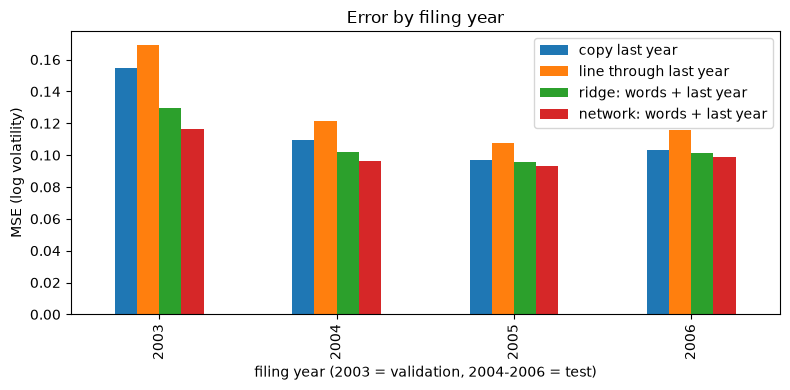

,copy last year,line through last year,ridge: words + last year,network: words + last year
2003,0.155,0.169,0.130,0.116
2004,0.109,0.121,0.102,0.096
2005,0.097,0.107,0.096,0.093
2006,0.103,0.116,0.102,0.099


In [10]:
# Error by filing year (validation year 2003, then test years): is the network better in some years only?
compare = ["copy last year", "line through last year", "ridge: words + last year", "network: words + last year"]
rows_vt = np.concatenate([idx["validate"], idx["test"]])
per_year = pd.DataFrame({
    name: pd.Series((y[rows_vt] - np.concatenate([results[name]["validate"][0], results[name]["test"][0]])) ** 2)
            .groupby(year_arr[rows_vt]).mean()
    for name in compare if name in results})
ax = per_year.plot.bar(figsize=(8, 4))
ax.set_xlabel("filing year (2003 = validation, 2004-2006 = test)")
ax.set_ylabel("MSE (log volatility)")
ax.set_title("Error by filing year")
plt.tight_layout()
plt.show()
per_year.round(3)

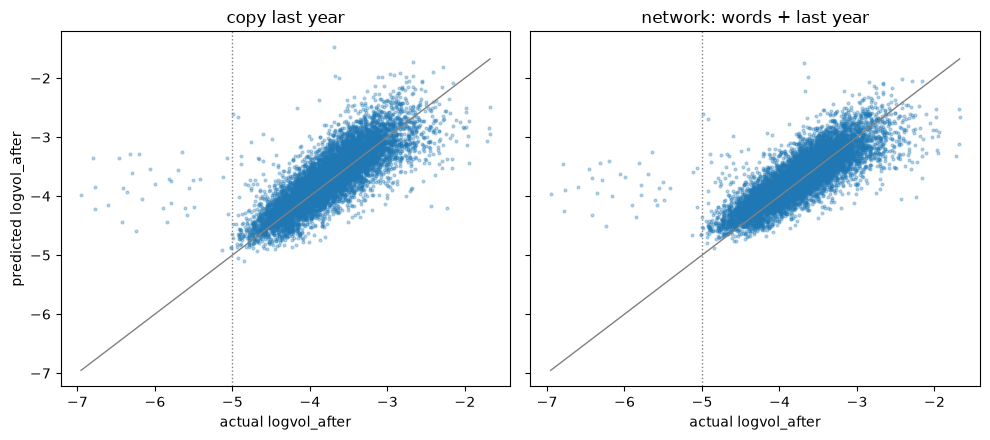

In [11]:
# Predicted against actual on the test years: baseline on the left, network on the right
yt = y[idx["test"]]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, name in zip(axes, ["copy last year", "network: words + last year"]):
    if name not in results:
        continue
    ax.scatter(yt, results[name]["test"][0], s=4, alpha=0.3)
    lims = [yt.min(), yt.max()]
    ax.plot(lims, lims, color="grey", lw=1)
    ax.axvline(VERY_LOW, color="grey", ls=":", lw=1)
    ax.set_xlabel("actual logvol_after")
    ax.set_title(name)
axes[0].set_ylabel("predicted logvol_after")
plt.tight_layout()
plt.show()

The dotted vertical line marks the very-low reports (takeovers). A model that cannot see them coming predicts "normal" for them, which shows up as points far above the diagonal on the left of the plot.

## 6. Which words does it use?

Two views, both rough.

- **Ridge coefficients** (words only): each word's weight in a linear model. Positive means "higher volatility next year".
- **Gradient × input** for the network (words + last year): for each report, how much the prediction would change per unit change in a word's feature, multiplied by the feature value itself; averaged over test reports. Unlike ridge, the network can combine words, so this is a local approximation, not a weight.

In `04-Volatility-Checking.ipynb` we expected distress wording (bankruptcy, going concern) to push volatility up and takeover wording (merger, tender offer) to push it down. These are single words here, so only parts of those phrases appear.

In [12]:
coef = ridge_text.coef_
order = np.argsort(coef)
print("ridge, words only -- push volatility DOWN:", [vocab[j] for j in order[:15]])
print("ridge, words only -- push volatility UP:  ", [vocab[j] for j in order[::-1][:15]])

probe = ["merger", "tender", "acquisition", "bankruptcy", "chapter", "delisted", "default", "going", "concern"]
print("\nwords we expect to matter (ridge coefficient, log-volatility per unit of feature):")
print({w: round(float(coef[word_index[w]]), 3) for w in probe if w in word_index})

ridge, words only -- push volatility DOWN: ['properties', 'dividends', 'effective', 'unsecured', 'lifo', 'distributions', 'rate', 'libor', 'increase', 'repayments', 'bottling', 'fhlb', 'propane', 'ridge', 'reinvestment']
ridge, words only -- push volatility UP:   ['loss', 'concern', 'decrease', 'covenants', 'going', 'obligations', 'experienced', 'nasdaq', 'securitizations', 'asbestos', 'reciprocal', 'overhead', 'lae', 'underperforming', 'remodeling']

words we expect to matter (ridge coefficient, log-volatility per unit of feature):
{'merger': -0.354, 'tender': -0.473, 'acquisition': -0.494, 'bankruptcy': -0.131, 'chapter': 0.326, 'default': 0.657, 'going': 0.898, 'concern': 1.036}


In [13]:
model = models[(True, 0)]
model.eval()
rng = np.random.default_rng(0)
sample = rng.choice(idx["test"], size=min(2000, len(idx["test"])), replace=False)
attr = np.zeros(X.shape[1])
for i in range(0, len(sample), 500):
    r = sample[i:i + 500]
    xb = dense(r).requires_grad_(True)
    model(xb, torch.from_numpy(prev_z[r])).sum().backward()
    attr += (xb.grad * xb).sum(dim=0).detach().cpu().numpy()
attr /= len(sample)
order = np.argsort(attr)
print("network, words + last year -- push the prediction DOWN:", [vocab[j] for j in order[:15]])
print("network, words + last year -- push the prediction UP:  ", [vocab[j] for j in order[::-1][:15]])

network, words + last year -- push the prediction DOWN: ['contents', 'fin', 'stockbased', 'risk', 'improved', 'segment', 'audit', 'corrections', 'rates', 'cumulative', 'positive', 'growth', 'exit', 'adopted', 'generally']
network, words + last year -- push the prediction UP:   ['issue', 'review', 'potential', 'covenants', 'history', 'convertible', 'lease', 'loss', 'minimum', 'evaluating', 'sfas', 'adverse', 'additional', 'raise', 'compliance']


## 7. Computational cost and the 1000× question

Assessment 2 asks how the approach behaves if the data grew by a factor of 1000. Here we only **measure** on this dataset and see what that implies; the argument for the real scaling design (Spark/Dask for counting, GPUs for training) comes in the report.

Three things are measured:

1. **Counting words**: time for the vocabulary pass and the counting pass (saved earlier).
2. **Training**: seconds per epoch for 10%, 25%, 50% and 100% of the training reports. If time per epoch grows in proportion to the number of reports, the log-log slope is about 1.
3. **Memory**: size of the sparse table, and how it would grow.

The same runs give a **learning curve** (validation error against training size), which says whether more data would even help this model.

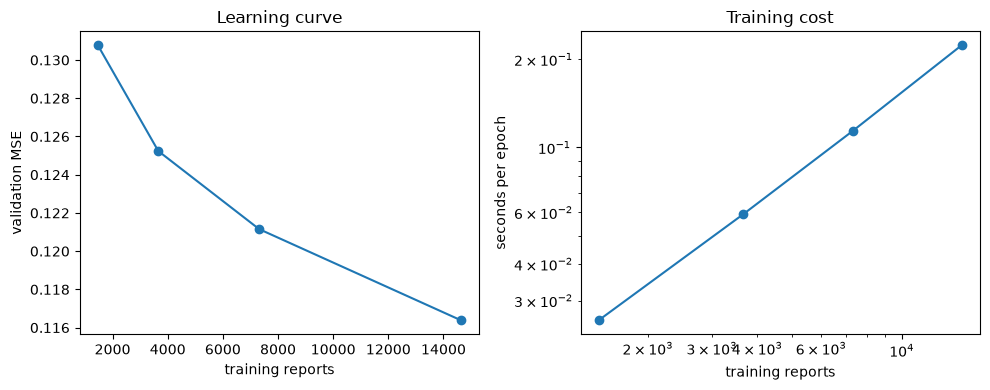

log-log slope of seconds per epoch against training reports: 0.94  (1.0 = cost grows in step with data)


,fraction,n_train,epochs,val_mse,sec_per_epoch,total_seconds
0,0.10,1463,18,0.131,0.026,0.995
1,0.25,3658,13,0.125,0.059,1.130
2,0.50,7316,15,0.121,0.114,2.099
3,1.00,14633,12,0.116,0.224,3.004


In [14]:
# Learning curve and training cost against training-set size (one seed each; text + last year network)
rng = np.random.default_rng(0)
rows_ = []
for frac in [0.1, 0.25, 0.5, 1.0]:
    sub = tr if frac == 1.0 else rng.choice(tr, size=int(frac * len(tr)), replace=False)
    t0 = time.perf_counter()
    _, hist = train_nn(sub, use_prev=True, seed=0)
    rows_.append({"fraction": frac, "n_train": len(sub), "epochs": len(hist), "val_mse": hist["val_mse"].min(),
                  "sec_per_epoch": hist["seconds"].mean(), "total_seconds": time.perf_counter() - t0})
lc = pd.DataFrame(rows_)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(lc["n_train"], lc["val_mse"], "o-")
axes[0].set_xlabel("training reports"); axes[0].set_ylabel("validation MSE"); axes[0].set_title("Learning curve")
axes[1].loglog(lc["n_train"], lc["sec_per_epoch"], "o-")
axes[1].set_xlabel("training reports"); axes[1].set_ylabel("seconds per epoch"); axes[1].set_title("Training cost")
plt.tight_layout()
plt.show()

slope_time = np.polyfit(np.log(lc["n_train"]), np.log(lc["sec_per_epoch"]), 1)[0]
print(f"log-log slope of seconds per epoch against training reports: {slope_time:.2f}  (1.0 = cost grows in step with data)")
lc.round(3)

In [15]:
# What the measurements imply if everything is simply multiplied by 1000 (a back-of-envelope, not a forecast)
FACTOR = 1000
full = lc.iloc[-1]
csr_bytes = X.data.nbytes + X.indices.nbytes + X.indptr.nbytes
n_params = sum(p.numel() for p in models[(True, 0)].parameters())
count_secs = timings["fit_vocab_seconds"] + timings["count_all_seconds"]

print(f"reports: {len(data):,}  ->  {len(data) * FACTOR:,.0f}")
print(f"sparse feature table: {csr_bytes / 1e6:,.0f} MB  ->  {csr_bytes * FACTOR / 1e9:,.0f} GB   ({csr_bytes / len(data) / 1e3:.0f} kB per report)")
print(f"counting words (both passes, one core): {count_secs / 60:,.1f} min  ->  {count_secs * FACTOR / 3600:,.0f} hours")
print(f"one training epoch: {full['sec_per_epoch']:.1f} s  ->  {full['sec_per_epoch'] * FACTOR / 3600:,.1f} hours (if cost is linear in data)")
print(f"network parameters: {n_params:,} (fixed by vocabulary size and hidden width, not by number of reports)")

reports: 27,142  ->  27,142,000
sparse feature table: 190 MB  ->  190 GB   (7 kB per report)
counting words (both passes, one core): 9.6 min  ->  160 hours
one training epoch: 0.2 s  ->  0.1 hours (if cost is linear in data)
network parameters: 320,131 (fixed by vocabulary size and hidden width, not by number of reports)


**Reading these numbers.**

- The network's size depends on the vocabulary (5,000) and hidden width (64), not on the number of reports, so the model itself does not grow with the data; the data pipeline and the epoch time do.
- Counting words is independent for each report, so it splits across machines with no coordination (a map step). The vocabulary pass needs a global count, which is a reduce step, or can be avoided with hashed features.
- Training is a sum over mini-batches, so batches can be spread over several GPUs with gradients averaged between them (data parallelism).
- The back-of-envelope above assumes one core and cost linear in the data; it shows why a single machine does not scale, not what a cluster would achieve. Measuring a real speed-up needs the same code on more workers.

## 8. Limitations and next steps

- **One vocabulary, one split.** The scores come from one time split and a vocabulary built on 1996–2002; a rolling split (train up to year $t$, test on $t+1$) would show how stable the result is.
- **Text source.** With Kogan-only text, 03 found Kogan's Item 7 is sometimes cut off at a cross-reference or includes Item 7A, so some reports have partial or extra text. With the EDGAR rule, about 3% of reports use Kogan's text (lower-cased, hyphens removed) and the vocabulary mixes the two tokenisations. Re-run once the matched EDGAR files are available and compare.
- **Bag of words ignores order.** "No substantial doubt" and "substantial doubt" count the same words. This is the gap FinBERT is meant to close.
- **Heavy tail.** Takeovers (very low volatility) and near-bankruptcies (very high) are a small share of reports but a large share of the squared error; MSE rewards getting these right, which may flatter or punish a model depending on whether it catches them.
- **Next:** the same inputs through FinBERT embeddings in place of word counts, keeping the split, skip connection and baselines identical, so any gain can be put down to the text representation.